# PTB: SDQT group comparison (MI vs healthy)

Ultra-short (15 s) segments, `filter_cfg == "own"`. Mann-Whitney U test per method (i2dsw, neurokit) on SDQT.

In [1]:
import pandas as pd
from scipy.stats import mannwhitneyu

df = pd.read_csv("../../results/ptb_full_v2.csv")
df = df[df["status"] == "ok"]
print(df.columns.tolist())
df.head()

['record_id', 'subject_id', 'group', 'age', 'sex', 'method', 'filter_cfg', 'segment_length_s', 'record_duration_s', 'n_r_peaks', 'n_beats_raw', 'threshold_uv', 'n_kept', 'n_total', 'n_failed', 'n_adapt_rejected', 'n_implausible', 'n_t_amp_nan', 'n_iso_fallback', 'n_rejected', 'n_beats', 'below_min_beats', 'sdqt', 'sdrt', 'qtvi', 'qt_mean', 'rr_mean', 'sdnn', 't_amp_median', 'adapt_distance_median', 'adapt_distance_max', 'align_shift_mean_ms', 'align_shift_max_ms', 'align_corr_mean', 'n_align_unusable', 'elapsed_s', 'status', 'error']


,record_id,subject_id,group,age,sex,method,filter_cfg,segment_length_s,record_duration_s,n_r_peaks,...,t_amp_median,adapt_distance_median,adapt_distance_max,align_shift_mean_ms,align_shift_max_ms,align_corr_mean,n_align_unusable,elapsed_s,status,error
0,s0026lre,patient007,MI,70.0,male,neurokit,own,full,115.2,142.0,...,158.853184,NaN,NaN,0.507042,4.0,0.994785,0.0,1.3,ok,NaN
2,s0026lre,patient007,MI,70.0,male,i2dsw,own,full,115.2,142.0,...,163.556906,9.724916,13.421366,0.507042,4.0,0.994785,0.0,48.8,ok,NaN
3,s0026lre,patient007,MI,70.0,male,i2dsw,orini,full,115.2,142.0,...,144.293445,3.819314,5.798886,1.654930,13.0,0.998152,0.0,97.6,ok,NaN
4,s0026lre,patient007,MI,70.0,male,neurokit,own,60,115.2,74.0,...,155.862100,NaN,NaN,0.702703,3.0,0.994749,0.0,0.7,ok,NaN
6,s0026lre,patient007,MI,70.0,male,i2dsw,own,60,115.2,74.0,...,160.451049,10.128080,13.379167,0.702703,3.0,0.994749,0.0,22.7,ok,NaN


In [2]:
# duration is stored as segment_length_s (string-valued, e.g. "15", "30", "full")
sub = df[(df["filter_cfg"] == "own") & (df["segment_length_s"].astype(str) == "15")]
sub["group"].value_counts(), sub["method"].value_counts()

(group
 MI         181
 healthy    103
 Name: count, dtype: int64,
 method
 i2dsw       143
 neurokit    141
 Name: count, dtype: int64)

In [3]:
rows = []
for method in ["i2dsw", "neurokit"]:
    m = sub[sub["method"] == method]
    mi = m.loc[m["group"] == "MI", "sdqt"].dropna()
    healthy = m.loc[m["group"] == "healthy", "sdqt"].dropna()

    u_stat, p_value = mannwhitneyu(mi, healthy, alternative="two-sided")

    rows.append({
        "method": method,
        "n_mi": len(mi),
        "n_healthy": len(healthy),
        "median_mi": mi.median(),
        "median_healthy": healthy.median(),
        "u_stat": u_stat,
        "p_value": p_value,
    })

results = pd.DataFrame(rows, columns=[
    "method", "n_mi", "n_healthy", "median_mi", "median_healthy", "u_stat", "p_value",
])
results

,method,n_mi,n_healthy,median_mi,median_healthy,u_stat,p_value
0,i2dsw,91,52,4.082889,2.574394,3213.0,3.818066e-04
1,neurokit,90,51,21.911227,8.025404,3442.0,8.679971e-07


# PTB: SDQT across segment lengths (Friedman test)

`filter_cfg == "own"`, MI and healthy combined. For each method, compare SDQT across the five segment lengths (`duration_cfg`, i.e. `segment_length_s`) within the same subjects using `scipy.stats.friedmanchisquare`. Subjects missing SDQT at any segment length are dropped.

In [4]:
from scipy.stats import friedmanchisquare

# duration_cfg is stored as segment_length_s in this dataset
df_own = df[df["filter_cfg"] == "own"]
df_own["segment_length_s"].unique()

array(['full', '60', '30', '15', '10'], dtype=object)

In [5]:
durations = ["10", "15", "30", "60", "full"]

friedman_rows = []
for method in ["i2dsw", "neurokit"]:
    m = df_own[df_own["method"] == method]

    pivot = m.pivot_table(index="subject_id", columns="segment_length_s", values="sdqt", aggfunc="first")
    pivot = pivot.reindex(columns=durations)

    n_total = pivot.shape[0]
    complete = pivot.dropna()
    n_used = complete.shape[0]
    n_dropped = n_total - n_used

    stat, p_value = friedmanchisquare(*[complete[d] for d in durations])
    medians = complete.median()

    friedman_rows.append({
        "method": method,
        "n_subjects_used": n_used,
        "n_subjects_dropped": n_dropped,
        **{f"median_sdqt_{d}": medians[d] for d in durations},
        "chi2_stat": stat,
        "p_value": p_value,
    })

friedman_results = pd.DataFrame(friedman_rows, columns=[
    "method", "n_subjects_used", "n_subjects_dropped",
    *[f"median_sdqt_{d}" for d in durations],
    "chi2_stat", "p_value",
])
friedman_results

,method,n_subjects_used,n_subjects_dropped,median_sdqt_10,median_sdqt_15,median_sdqt_30,median_sdqt_60,median_sdqt_full,chi2_stat,p_value
0,i2dsw,142,1,2.770819,3.343819,3.652834,4.098699,4.765337,133.356362,7.455599e-28
1,neurokit,140,3,15.318977,16.079264,19.527522,19.589272,18.476772,29.994286,4.907565e-06


# PTB: runtime by segment length (i2dsw, own filter)

Jittered scatter of `elapsed_s`, separated by segment length, `filter_cfg == "own"`, `method == "i2dsw"` only. Same thesis plotting style as `own_synthetic.ipynb`.

saved ptb_i2dsw_runtime.pdf / .png -> ../../figures


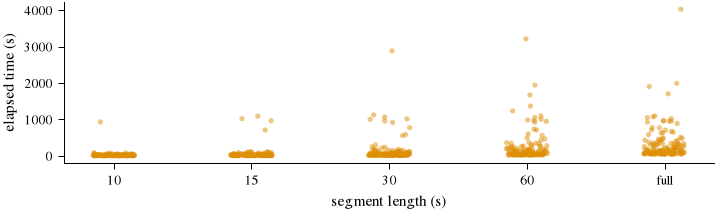

In [6]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, "../..")
from src.tests.style import set_thesis_style, save, TEXT_WIDTH_IN, ORANGE

out_dir = Path("../../figures")

_runtime_df = df[(df["filter_cfg"] == "own") & (df["method"] == "i2dsw")]
_durations = ["10", "15", "30", "60", "full"]

plt.rcdefaults()
set_thesis_style(use_tex=False)

fig, ax = plt.subplots(figsize=(TEXT_WIDTH_IN, 2))

positions = np.arange(len(_durations))
rng = np.random.default_rng(0)

for i, d in enumerate(_durations):
    vals = _runtime_df[_runtime_df["segment_length_s"] == d]["elapsed_s"]
    jitter = rng.uniform(-0.15, 0.15, size=len(vals))
    ax.scatter(
        positions[i] + jitter,
        vals,
        color=ORANGE,
        alpha=0.5,
        s=10,
        edgecolors="none",
    )

ax.set_xticks(positions)
ax.set_xticklabels(_durations)
ax.set_xlabel("segment length (s)")
ax.set_ylabel("elapsed time (s)")
fig.tight_layout()
save(fig, "ptb_i2dsw_runtime", out_dir)
plt.show()

In [7]:
# Mean & median runtime (elapsed_s) per segment length, i2dsw + own filter
_runtime_mean = _runtime_df.groupby("segment_length_s")["elapsed_s"].mean().reindex(_durations)
_runtime_median = _runtime_df.groupby("segment_length_s")["elapsed_s"].median().reindex(_durations)
pd.DataFrame({"mean_elapsed_s": _runtime_mean, "median_elapsed_s": _runtime_median})

,mean_elapsed_s,median_elapsed_s
segment_length_s,,
10,21.735211,10.4
15,50.260140,13.7
30,123.164336,30.6
60,225.409091,72.9
full,317.816783,149.9


saved ptb_i2dsw_runtime_vs_length.pdf / .png -> ../../figures


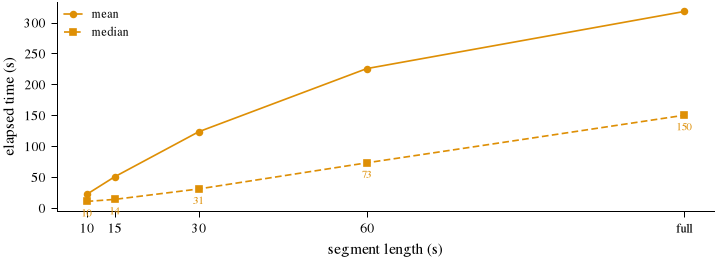

In [8]:
# Mean & median runtime vs. segment length: linear axes, x-values spaced by actual segment length
_numeric_len = {
    "10": 10, "15": 15, "30": 30, "60": 60,
    "full": _runtime_df.loc[_runtime_df["segment_length_s"] == "full", "record_duration_s"].mean(),
}
_x = np.array([_numeric_len[d] for d in _durations])
_y_mean = _runtime_mean.values
_y_median = _runtime_df.groupby("segment_length_s")["elapsed_s"].median().reindex(_durations).values

plt.rcdefaults()
set_thesis_style(use_tex=False)

fig, ax = plt.subplots(figsize=(TEXT_WIDTH_IN, 2.4))
ax.plot(_x, _y_mean, marker="o", ms=3.5, lw=1.0, color=ORANGE, label="mean")
ax.plot(_x, _y_median, marker="s", ms=3.5, lw=1.0, color=ORANGE, ls=(0, (4, 2)), label="median")

for xi, yi in zip(_x, _y_median):
    ax.annotate(f"{yi:.0f}", (xi, yi), textcoords="offset points", xytext=(0, -9),
                ha="center", fontsize=6.5, color=ORANGE)

ax.set_xticks(_x)
ax.set_xticklabels(_durations)
ax.set_xlabel("segment length (s)")
ax.set_ylabel("elapsed time (s)")
ax.legend(loc="upper left", fontsize=7, handlelength=1.6, borderaxespad=0.2)
fig.tight_layout()
save(fig, "ptb_i2dsw_runtime_vs_length", out_dir)
plt.show()

# PTB: SDQT, 15 s vs. full (paired Wilcoxon)

`filter_cfg == "own"`, MI and healthy combined. For each method, pivot `subject_id` x segment length on `sdqt` for the "15" and "full" lengths, drop subjects missing either, and run a paired `scipy.stats.wilcoxon` signed-rank test.

In [9]:
from scipy.stats import wilcoxon

wilcoxon_rows = []
for method in ["i2dsw", "neurokit"]:
    m = df_own[df_own["method"] == method]

    pivot = m.pivot_table(index="subject_id", columns="segment_length_s", values="sdqt", aggfunc="first")
    pivot = pivot[["15", "full"]].dropna()

    stat, p_value = wilcoxon(pivot["15"], pivot["full"])

    wilcoxon_rows.append({
        "method": method,
        "n_pairs": len(pivot),
        "median_15": pivot["15"].median(),
        "median_full": pivot["full"].median(),
        "wilcoxon_stat": stat,
        "p_value": p_value,
    })

wilcoxon_results = pd.DataFrame(wilcoxon_rows, columns=[
    "method", "n_pairs", "median_15", "median_full", "wilcoxon_stat", "p_value",
])
wilcoxon_results

,method,n_pairs,median_15,median_full,wilcoxon_stat,p_value
0,i2dsw,143,3.311573,4.771459,1367.0,2.548121e-14
1,neurokit,141,15.688665,18.362986,3685.0,6.574293e-03


# PTB: SDQT, 15 s vs. full (Spearman correlation)

`filter_cfg == "own"`, MI and healthy combined. Same pairs as the paired Wilcoxon test above (per method, subjects with a valid SDQT at both "15" and "full" pivoted from `df_own`). For each method: `scipy.stats.spearmanr` between the 15 s and full-length SDQT values.

In [10]:
from scipy.stats import spearmanr

spearman_rows = []
for method in ["i2dsw", "neurokit"]:
    m = df_own[df_own["method"] == method]

    pivot = m.pivot_table(index="subject_id", columns="segment_length_s", values="sdqt", aggfunc="first")
    pivot = pivot[["15", "full"]].dropna()

    rho, p_value = spearmanr(pivot["15"], pivot["full"])

    spearman_rows.append({
        "method": method,
        "n_pairs": len(pivot),
        "spearman_rho": rho,
        "p_value": p_value,
    })

spearman_results = pd.DataFrame(spearman_rows, columns=[
    "method", "n_pairs", "spearman_rho", "p_value",
])
spearman_results

,method,n_pairs,spearman_rho,p_value
0,i2dsw,143,0.774844,7.099620e-30
1,neurokit,141,0.837544,2.605737e-38


# PTB: QTVI group comparison (MI vs healthy)

Ultra-short (15 s) segments, `filter_cfg == "own"`. Mann-Whitney U test per method (i2dsw, neurokit) on QTVI. Same structure as the SDQT analysis above, using `qtvi` instead. A handful of `qtvi` values are `-inf` (degenerate cases); these are dropped alongside NaNs.

In [11]:
qtvi_rows = []
for method in ["i2dsw", "neurokit"]:
    m = sub[sub["method"] == method]
    mi = m.loc[m["group"] == "MI", "qtvi"].replace([np.inf, -np.inf], np.nan).dropna()
    healthy = m.loc[m["group"] == "healthy", "qtvi"].replace([np.inf, -np.inf], np.nan).dropna()

    u_stat, p_value = mannwhitneyu(mi, healthy, alternative="two-sided")

    qtvi_rows.append({
        "method": method,
        "n_mi": len(mi),
        "n_healthy": len(healthy),
        "median_mi": mi.median(),
        "median_healthy": healthy.median(),
        "u_stat": u_stat,
        "p_value": p_value,
    })

qtvi_results = pd.DataFrame(qtvi_rows, columns=[
    "method", "n_mi", "n_healthy", "median_mi", "median_healthy", "u_stat", "p_value",
])
qtvi_results

,method,n_mi,n_healthy,median_mi,median_healthy,u_stat,p_value
0,i2dsw,89,51,-0.438190,-1.465670,3653.0,2.116936e-09
1,neurokit,90,51,0.976617,-0.493057,3660.0,4.775230e-09


# PTB: QTVI, 15 s vs. full (paired Wilcoxon)

`filter_cfg == "own"`, MI and healthy combined. Same structure as the SDQT paired test above, using `qtvi`.

In [12]:
qtvi_wilcoxon_rows = []
for method in ["i2dsw", "neurokit"]:
    m = df_own[df_own["method"] == method]

    pivot = m.pivot_table(index="subject_id", columns="segment_length_s", values="qtvi", aggfunc="first")
    pivot = pivot[["15", "full"]].replace([np.inf, -np.inf], np.nan).dropna()

    stat, p_value = wilcoxon(pivot["15"], pivot["full"])

    qtvi_wilcoxon_rows.append({
        "method": method,
        "n_pairs": len(pivot),
        "median_15": pivot["15"].median(),
        "median_full": pivot["full"].median(),
        "wilcoxon_stat": stat,
        "p_value": p_value,
    })

qtvi_wilcoxon_results = pd.DataFrame(qtvi_wilcoxon_rows, columns=[
    "method", "n_pairs", "median_15", "median_full", "wilcoxon_stat", "p_value",
])
qtvi_wilcoxon_results

,method,n_pairs,median_15,median_full,wilcoxon_stat,p_value
0,i2dsw,140,-0.968322,-1.059673,3613.0,0.005962
1,neurokit,141,0.552327,0.225167,2647.0,0.000001


In [13]:
qtvi_median = (
    df_own
    .replace([np.inf, -np.inf], np.nan)
    .groupby(["method", "group", "segment_length_s"])["qtvi"]
    .median()
    .unstack("segment_length_s")
    .reindex(columns=durations)
)
qtvi_median

/var/folders/vv/k53m9jpx7pb3swg73f2s46ch0000gn/T/ipykernel_4708/2660656742.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace([np.inf, -np.inf], np.nan)


segment_length_s        10        15        30        60      full
method   group                                                    
i2dsw    MI      -0.320655 -0.438190 -0.389031 -0.457765 -0.607073
         healthy -1.286557 -1.465670 -1.442704 -1.447331 -1.463582
neurokit MI       1.060554  0.976617  0.859988  0.808441  0.800224
         healthy -0.176401 -0.493057 -0.342675 -0.394223 -0.384407

# PTB: beat-funnel counters (15 s, own filter)

`filter_cfg == "own"`, `segment_length_s == "15"`. Mean beat-funnel counters per group and method.

In [14]:
_cols = ["n_total", "n_failed", "n_rejected", "n_beats", "n_iso_fallback", "n_t_amp_nan"]

counters_table = sub.groupby(["group", "method"])[_cols].mean()

# rows with status == "failed" (excluded from `df`/`sub` above, which are filtered to status == "ok")
raw = pd.read_csv("../../results/ptb_full_v2.csv")
raw_sub = raw[(raw["filter_cfg"] == "own") & (raw["segment_length_s"].astype(str) == "15")]
n_status_failed = (
    raw_sub[raw_sub["status"] == "failed"]
    .groupby(["group", "method"])
    .size()
    .reindex(counters_table.index, fill_value=0)
)
counters_table["n_status_failed"] = n_status_failed
counters_table

n_total  n_failed  n_rejected    n_beats  n_iso_fallback  \
group   method                                                                 
MI      i2dsw     18.109890  0.000000    0.153846  17.956044        2.109890   
        neurokit  19.122222  0.422222    2.444444  16.677778        0.022222   
healthy i2dsw     16.173077  0.000000    0.000000  16.173077        3.634615   
        neurokit  17.313725  0.450980    1.980392  15.333333        0.058824   

                  n_t_amp_nan  n_status_failed  
group   method                                  
MI      i2dsw        0.120879                0  
        neurokit     0.877778                1  
healthy i2dsw        0.000000                0  
        neurokit     1.607843                1

# PTB: impact of below-minimum-beat records on SDQT (15 s, own filter)

`filter_cfg == "own"`, `segment_length_s == "15"`. Per group and method: fraction of records with `below_min_beats == 1` (i.e. `n_beats < 8`), median SDQT including vs. excluding those records, and the absolute/relative difference between the two medians.

In [15]:
below_min_rows = []
for (grp, method), m in sub.groupby(["group", "method"]):
    frac_below = (m["below_min_beats"] == 1).mean()
    median_all = m["sdqt"].median()
    median_excl = m.loc[m["below_min_beats"] == 0, "sdqt"].median()
    abs_diff = median_excl - median_all
    rel_diff = abs_diff / median_all

    below_min_rows.append({
        "group": grp,
        "method": method,
        "frac_below_min_beats": frac_below,
        "median_sdqt_all": median_all,
        "median_sdqt_excl_below_min": median_excl,
        "abs_diff": abs_diff,
        "rel_diff": rel_diff,
    })

below_min_results = pd.DataFrame(below_min_rows, columns=[
    "group", "method", "frac_below_min_beats",
    "median_sdqt_all", "median_sdqt_excl_below_min", "abs_diff", "rel_diff",
])
below_min_results

,group,method,frac_below_min_beats,median_sdqt_all,median_sdqt_excl_below_min,abs_diff,rel_diff
0,MI,i2dsw,0.000000,4.082889,4.082889,0.000000,0.000000
1,MI,neurokit,0.055556,21.911227,21.792620,-0.118606,-0.005413
2,healthy,i2dsw,0.000000,2.574394,2.574394,0.000000,0.000000
3,healthy,neurokit,0.078431,8.025404,8.443465,0.418061,0.052092


# PTB: SDQT overview across segment lengths (own filter)

`filter_cfg == "own"`, `status == "ok"` (i.e. `df_own`, as defined above). Rows = (method, group), columns = the five `duration_cfg` values (`segment_length_s`: 10, 15, 30, 60, full). Each cell reports the median SDQT with the 25th/75th percentile in brackets, plus n per cell.

In [16]:
def _fmt_cell(vals):
    vals = vals.dropna()
    if len(vals) == 0:
        return "n=0"
    q25, med, q75 = vals.quantile([0.25, 0.5, 0.75])
    return f"{med:.2f} [{q25:.2f}, {q75:.2f}] (n={len(vals)})"

sdqt_overview = (
    df_own.groupby(["method", "group", "segment_length_s"])["sdqt"]
    .apply(_fmt_cell)
    .unstack("segment_length_s")
    .reindex(columns=durations)
)
sdqt_overview

segment_length_s                           10                           15  \
method   group                                                               
i2dsw    MI          3.52 [2.17, 6.06] (n=90)     4.08 [2.36, 6.43] (n=91)   
         healthy     2.31 [1.45, 3.15] (n=52)     2.57 [1.61, 3.72] (n=52)   
neurokit MI       20.67 [10.11, 30.69] (n=90)  21.91 [10.61, 31.34] (n=90)   
         healthy    6.45 [3.92, 17.52] (n=50)    8.03 [4.23, 20.22] (n=51)   

segment_length_s                           30                           60  \
method   group                                                               
i2dsw    MI          4.86 [3.07, 7.76] (n=91)     5.44 [3.72, 8.59] (n=91)   
         healthy     3.05 [2.14, 4.03] (n=52)     3.04 [2.25, 4.10] (n=52)   
neurokit MI       23.25 [14.44, 33.06] (n=90)  23.47 [14.94, 30.75] (n=91)   
         healthy    9.02 [3.97, 20.90] (n=51)    9.13 [5.00, 20.81] (n=51)   

segment_length_s                         full  
method   group                                 
i2dsw    MI          5.67 [3.83, 8.93] (n=91)  
         healthy     3.43 [2.53, 5.36] (n=52)  
neurokit MI       24.67 [14.75, 34.20] (n=91)  
         healthy    9.39 [4.87, 20.66] (n=52)

# PTB: beat-funnel and thresholding summary (15 s, own filter, i2dsw)

`status == "ok"`, `filter_cfg == "own"`, `segment_length_s == "15"`, `method == "i2dsw"`. Per group: mean `n_total`, `n_failed`, `n_adapt_rejected`, `n_rejected`, `n_beats`; the template usage ratio `n_kept / n_total`; and the fraction of records with an escalated Manhattan threshold (`threshold_uv > 30`).

In [17]:
funnel_df = df[
    (df["filter_cfg"] == "own")
    & (df["segment_length_s"].astype(str) == "15")
    & (df["method"] == "i2dsw")
]

_counter_cols = ["n_total", "n_failed", "n_adapt_rejected", "n_rejected", "n_beats"]

funnel_summary = funnel_df.groupby("group")[_counter_cols].mean()
funnel_summary["n_kept_ratio"] = (
    funnel_df.groupby("group")["n_kept"].mean() / funnel_summary["n_total"]
)
funnel_summary["frac_threshold_escalated"] = (
    funnel_df.groupby("group")["threshold_uv"].apply(lambda s: (s > 30).mean())
)
funnel_summary

,n_total,n_failed,n_adapt_rejected,n_rejected,n_beats,n_kept_ratio,frac_threshold_escalated
group,,,,,,,
MI,18.109890,0.0,0.120879,0.153846,17.956044,0.949636,0.010989
healthy,16.173077,0.0,0.000000,0.000000,16.173077,0.985731,0.000000


In [18]:
_latex_cols = {
    "n_total": "$n_\\mathrm{total}$",
    "n_failed": "$n_\\mathrm{failed}$",
    "n_adapt_rejected": "$n_\\mathrm{adapt.\\,rej.}$",
    "n_rejected": "$n_\\mathrm{rejected}$",
    "n_beats": "$n_\\mathrm{beats}$",
    "n_kept_ratio": "$n_\\mathrm{kept}/n_\\mathrm{total}$",
    "frac_threshold_escalated": "frac.\\ $\\theta_\\mathrm{uv} > 30$",
}

latex_table = funnel_summary.rename(columns=_latex_cols)
latex_table.index.name = "group"

print(latex_table.to_latex(
    float_format="%.2f",
    escape=False,
    column_format="l" + "r" * len(latex_table.columns),
    caption="Beat-funnel counters and thresholding summary, 15\\,s segments, own filter, i2dsw.",
    label="tab:ptb_funnel_15s_i2dsw",
    position="htbp",
    bold_rows=False,
))

\begin{table}[htbp]
\caption{Beat-funnel counters and thresholding summary, 15\,s segments, own filter, i2dsw.}
\label{tab:ptb_funnel_15s_i2dsw}
\begin{tabular}{lrrrrrrr}
\toprule
 & $n_\mathrm{total}$ & $n_\mathrm{failed}$ & $n_\mathrm{adapt.\,rej.}$ & $n_\mathrm{rejected}$ & $n_\mathrm{beats}$ & $n_\mathrm{kept}/n_\mathrm{total}$ & frac.\ $\theta_\mathrm{uv} > 30$ \\
group &  &  &  &  &  &  &  \\
\midrule
MI & 18.11 & 0.00 & 0.12 & 0.15 & 17.96 & 0.95 & 0.01 \\
healthy & 16.17 & 0.00 & 0.00 & 0.00 & 16.17 & 0.99 & 0.00 \\
\bottomrule
\end{tabular}
\end{table}



In [19]:
t_amp_mean_i2dsw = (
    sub[sub["method"] == "i2dsw"]
    .groupby("group")[["t_amp_median", "rr_mean", "sdnn"]]
    .mean()
)
t_amp_mean_i2dsw

,t_amp_median,rr_mean,sdnn
group,,,
MI,171.205454,795.448510,29.264889
healthy,319.086905,882.122577,37.968882
